# Machine Learning-Based Lung Cancer Risk Assessment and Classification

The primary objective of this project is to develop a machine learning-based system for assessing and classifying lung cancer risk using relevant lifestyle and health-related factors.

**dataset**
 
The dataset contains demographic, lifestyle and health-related information from individuals, including factors such as age, gender, smoking habits, and various reported symptoms associated with lung cancer. It includes a target variable indicating lung cancer risk, making it suitable for exploring relationships between these factors. [1] 

**project specific objectives** 
1. Data Preprocessing: Prepare and transform the dataset for model development.
2. Model Training and Evaluation: Train, compare and evaluate classification models.
3. Model Interpretation: Analyse model performance and identify influential features.
4. Model Deployment: Deploy the selected model through a simple, accessible web application. 

**References**

[1] ‘Lung Cancer’. Accessed: Nov. 19, 2026. [Online]. Available: https://www.kaggle.com/datasets/mysarahmadbhat/lung-cancer


In [56]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt 
import math
from pathlib import Path

**Load Dataset**

In [57]:
project_dir = Path.cwd()
data_dir = project_dir / "dataset" 

lung_cancer_df = pd.read_csv(data_dir / "survey_lung_cancer.csv")
lung_cancer_df.head()

,GENDER,AGE,SMOKING,YELLOW_FINGERS,ANXIETY,PEER_PRESSURE,CHRONIC DISEASE,FATIGUE,ALLERGY,WHEEZING,ALCOHOL CONSUMING,COUGHING,SHORTNESS OF BREATH,SWALLOWING DIFFICULTY,CHEST PAIN,LUNG_CANCER
0,M,69,1,2,2,1,1,2,1,2,2,2,2,2,2,YES
1,M,74,2,1,1,1,2,2,2,1,1,1,2,2,2,YES
2,F,59,1,1,1,2,1,2,1,2,1,2,2,1,2,NO
3,M,63,2,2,2,1,1,1,1,1,2,1,1,2,2,NO
4,F,63,1,2,1,1,1,1,1,2,1,2,2,1,1,NO


**Data pre-processing and Visualisation** 

- Check for missing and null values.
- Identify and handle duplicate records.
- Inspect data types and feature consistency.
- Identify and handle inconsistent or invalid values.

In [58]:
lung_cancer_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 309 entries, 0 to 308
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype
---  ------                 --------------  -----
 0   GENDER                 309 non-null    str  
 1   AGE                    309 non-null    int64
 2   SMOKING                309 non-null    int64
 3   YELLOW_FINGERS         309 non-null    int64
 4   ANXIETY                309 non-null    int64
 5   PEER_PRESSURE          309 non-null    int64
 6   CHRONIC DISEASE        309 non-null    int64
 7   FATIGUE                309 non-null    int64
 8   ALLERGY                309 non-null    int64
 9   WHEEZING               309 non-null    int64
 10  ALCOHOL CONSUMING      309 non-null    int64
 11  COUGHING               309 non-null    int64
 12  SHORTNESS OF BREATH    309 non-null    int64
 13  SWALLOWING DIFFICULTY  309 non-null    int64
 14  CHEST PAIN             309 non-null    int64
 15  LUNG_CANCER            309 non-null    str  
dtypes

In [59]:
lung_cancer_df.isnull().sum()

GENDER                   0
AGE                      0
SMOKING                  0
YELLOW_FINGERS           0
ANXIETY                  0
PEER_PRESSURE            0
CHRONIC DISEASE          0
FATIGUE                  0
ALLERGY                  0
WHEEZING                 0
ALCOHOL CONSUMING        0
COUGHING                 0
SHORTNESS OF BREATH      0
SWALLOWING DIFFICULTY    0
CHEST PAIN               0
LUNG_CANCER              0
dtype: int64

In [60]:
lung_cancer_df.duplicated().sum()

np.int64(33)

Drop duplicated rows from the dataframe

In [61]:
data_df = lung_cancer_df.drop_duplicates().reset_index(drop=True) # Remove duplicate rows


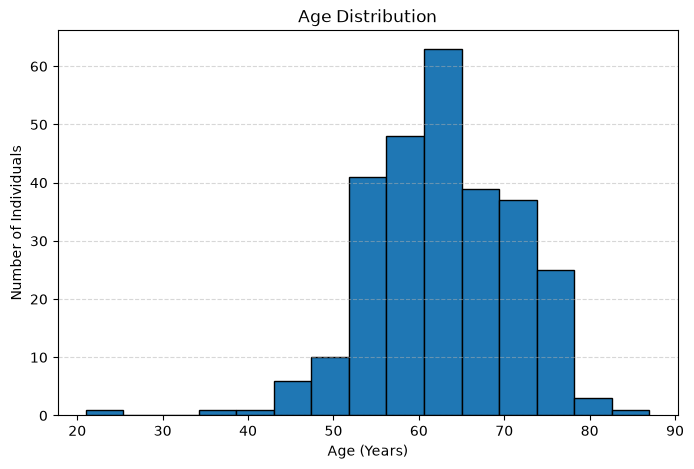

In [62]:
# Age Distribution Histogram
plt.figure(figsize=(8, 5))

plt.hist(data_df['AGE'], bins=15, edgecolor='black')

plt.title('Age Distribution')
plt.xlabel('Age (Years)')
plt.ylabel('Number of Individuals')

plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

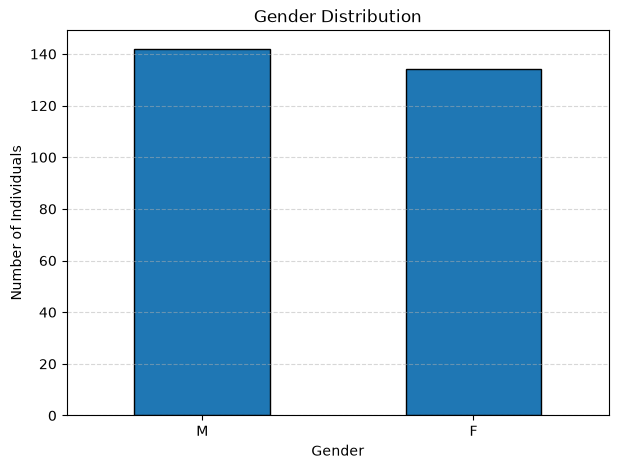

In [63]:
# Gender Distribution Bar Graph
gender_counts = data_df['GENDER'].value_counts()

plt.figure(figsize=(7, 5))
gender_counts.plot(kind='bar', edgecolor='black')

plt.title('Gender Distribution')
plt.xlabel('Gender')
plt.ylabel('Number of Individuals')
plt.xticks(rotation=0)

plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

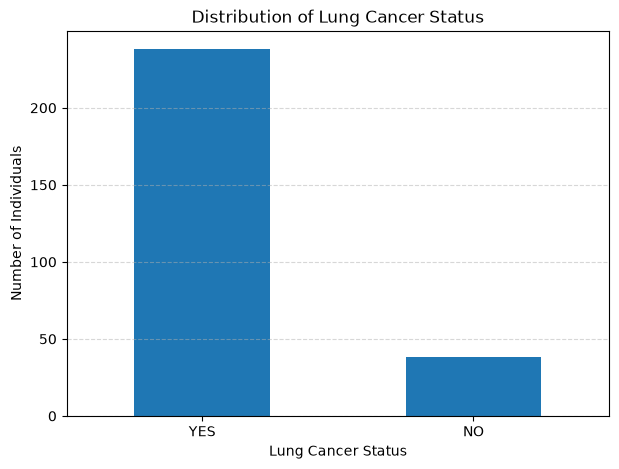

In [64]:
# Count records in each category
cancer_counts = data_df['LUNG_CANCER'].value_counts()

# Plot bar graph
plt.figure(figsize=(7, 5))
cancer_counts.plot(kind='bar')

plt.title('Distribution of Lung Cancer Status')
plt.xlabel('Lung Cancer Status')
plt.ylabel('Number of Individuals')
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.show()

**Class Imbalance Handling**

The dataset exhibits class imbalance, with significantly more YES than NO records.
Oversample the Dataset using SMOTENC to balance the classes.


In [65]:
import time
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC, SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, HistGradientBoostingClassifier

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay
from sklearn.inspection import permutation_importance

# Model training and evaluation

In [66]:
RANDOM_STATE = 42 # for reproducibility

models = {
    'Dummy (most frequent)': DummyClassifier(strategy='most_frequent'),
    'Logistic regression'  : LogisticRegression(max_iter=1000),
    'Linear SVC'           : LinearSVC(C=15, random_state=RANDOM_STATE),
    'k-NN'                 : KNeighborsClassifier(n_neighbors=30),
    'Random forest'        : RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
}

In [67]:
# This function was developed with assistance from ChatGPT
# to streamline model training and evaluation using Scikit-learn metrics.

def evaluate_models(models, X_train, X_test, y_train, y_test):

    rows, predictions = [], {}

    for name, model in models.items():

        start = time.perf_counter()
        model.fit(X_train, y_train)
        fit_time = time.perf_counter() - start

        y_pred = model.predict(X_test)
        predictions[name] = y_pred

        report = classification_report(
            y_test, y_pred,
            output_dict=True,
            zero_division=0
        )

        rows.append({
            'model': name,
            'accuracy': report['accuracy'],
            'macro precision': report['macro avg']['precision'],
            'macro recall': report['macro avg']['recall'],
            'macro F1': report['macro avg']['f1-score'],
            'weighted F1': report['weighted avg']['f1-score'],
            'fit time (s)': fit_time
        })

    results = (
        pd.DataFrame(rows)
        .set_index('model')
        .sort_values('macro F1', ascending=False)
    )

    # Plot confusion matrices
    labels = np.unique(
        np.concatenate([np.asarray(y_train), np.asarray(y_test)])
    )

    n_models = len(predictions)
    n_cols = 2
    n_rows = math.ceil(n_models / n_cols)

    fig, axes = plt.subplots(
        n_rows, n_cols,
        figsize=(12, 5 * n_rows),
        squeeze=False
    )

    for ax, (name, y_pred) in zip(axes.flat, predictions.items()):

        ConfusionMatrixDisplay.from_predictions(
            y_test,
            y_pred,
            labels=labels,
            display_labels=labels,
            normalize='true',
            values_format='.0%',
            cmap='Blues',
            colorbar=False,
            ax=ax
        )

        ax.set_title(name, fontsize=12, fontweight='bold')

    # Remove unused subplots
    for ax in axes.flat[n_models:]:
        fig.delaxes(ax)

    fig.suptitle(
        'Confusion Matrices for All Models',
        fontsize=15,
        fontweight='bold'
    )

    plt.tight_layout()
    plt.show()

    return results.round(3)

In [68]:
# replace categorical variables with numerical values 
encoder = LabelEncoder()
categorical_columns = ['GENDER', 'LUNG_CANCER']
for col in categorical_columns:
    data_df[col] = encoder.fit_transform(data_df[col]) 


**Train the model after correcting class imbalance**

In [69]:
# Split the dataset into features and target variable
X = data_df.drop('LUNG_CANCER', axis=1)
y = data_df['LUNG_CANCER'] 


In [70]:
# balanced training data using smote oversampling technique
from imblearn.over_sampling import SMOTENC 
from sklearn.model_selection import StratifiedKFold 

In [71]:
# Code developed with assistance from ChatGPT
# for categorical feature identification and SMOTENC implementation.

# Split the dataset into features and target variable.
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y # stratify the split to maintain the original class distribution
)

# Identify categorical features for SMOTENC.
# AGE is the only continuous feature, so we exclude it from the categorical features list.
categorical_features = [
    col for col in X_train.columns if col != 'AGE'
]

# Apply SMOTENC to balance the training dataset.
# The test dataset remains unchanged to prevent data leakage.
smotenc = SMOTENC(
    categorical_features=categorical_features,
    random_state=RANDOM_STATE
)

# Resample the training dataset using SMOTENC.
X_train_smotenc, y_train_smotenc = smotenc.fit_resample(
    X_train, y_train
)

# Inspect the resampled training dataset.
print("Resampled target distribution:")
print(y_train_smotenc.value_counts())

Resampled target distribution:
LUNG_CANCER
1    190
0    190
Name: count, dtype: int64


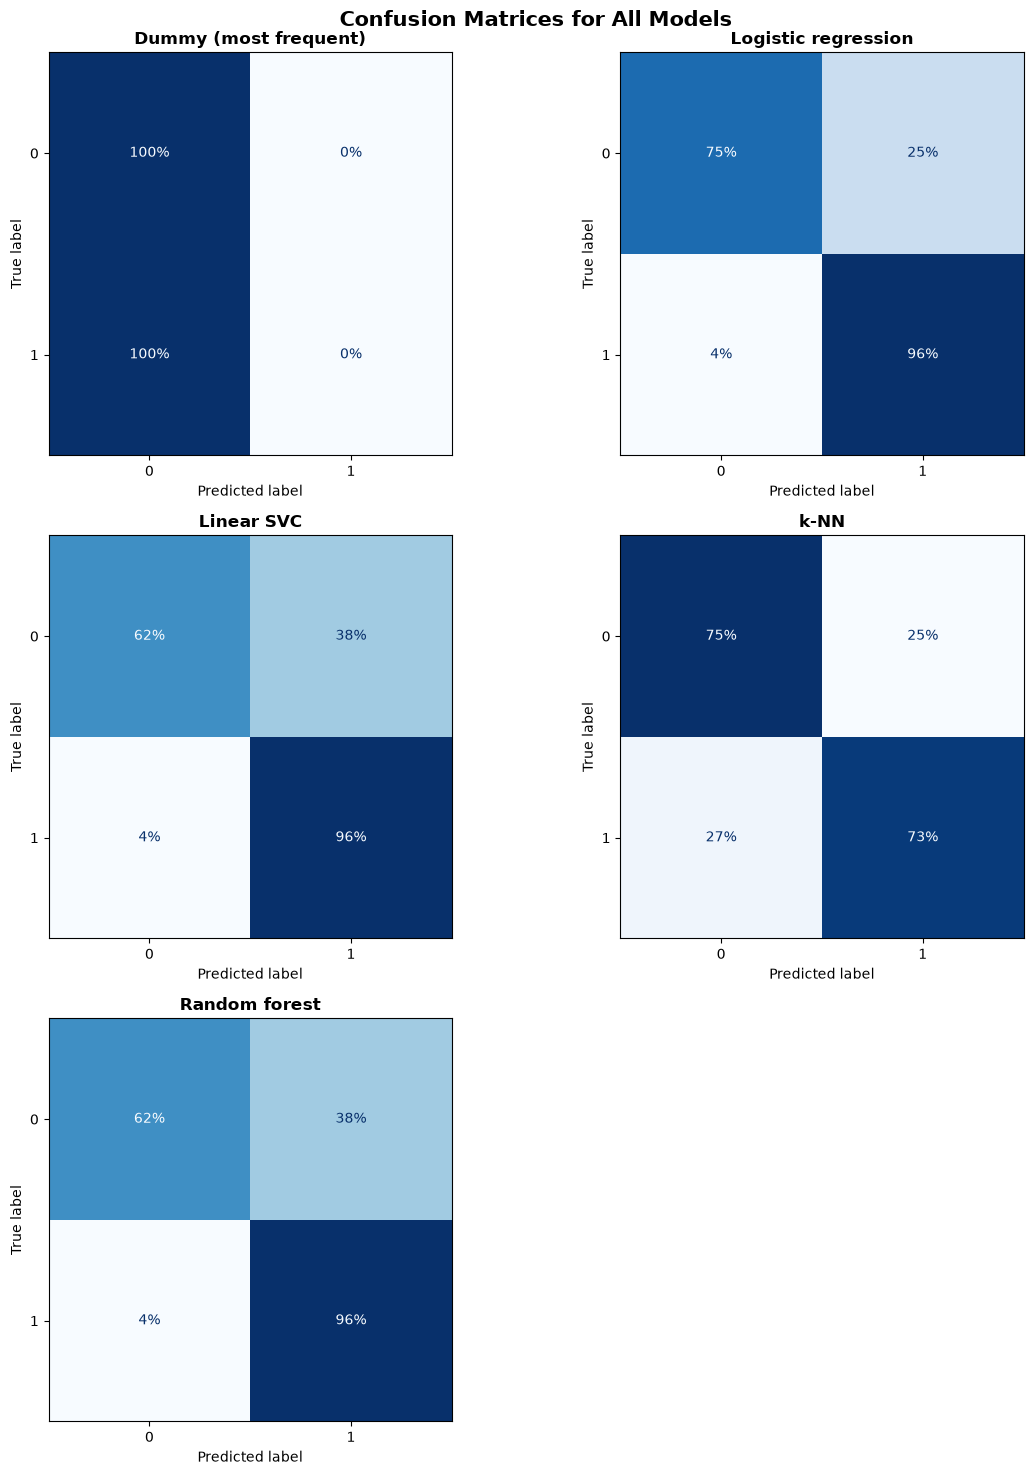

,accuracy,macro precision,macro recall,macro F1,weighted F1,fit time (s)
model,,,,,,
Logistic regression,0.929,0.854,0.854,0.854,0.929,0.041
Random forest,0.911,0.827,0.792,0.808,0.908,0.349
Linear SVC,0.911,0.827,0.792,0.808,0.908,0.004
k-NN,0.732,0.631,0.740,0.634,0.769,0.002
Dummy (most frequent),0.143,0.071,0.500,0.125,0.036,0.001


In [72]:
# train and evaluate the models on the resampled training data
results_resampled = evaluate_models(models, X_train_smotenc, X_test, y_train_smotenc, y_test)
results_resampled

# Model optimisation
**Hyperparameter tuning to for the two best performing models**

In [ ]:
# Hyperparameter tuning for Logistic Regression and Random Forest models using GridSearchCV.
models_to_tune = {
    'Logistic regression': models['Logistic regression'],
    'Random forest': models['Random forest']
}

param_grids = {

    'Logistic regression': {
        'C': [0.01, 0.1, 1, 10, 100],
        'penalty': ['l1', 'l2'],
        'solver': ['liblinear', 'saga'],
        'class_weight': [None, 'balanced']
    },

    'Random forest': {
        'n_estimators': [100, 200, 300],
        'max_depth': [None, 5, 10, 20],
        'min_samples_split': [2, 5, 10],
        'min_samples_leaf': [1, 2, 4],
        'max_features': ['sqrt', 'log2'],
        'class_weight': [None, 'balanced']
    }
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)


In [ ]:
# Hyperparameter tuning using GridSearchCV

from sklearn.model_selection import GridSearchCV 

best_models = {}
tuning_results = []

for name, model in models_to_tune.items():

    search = GridSearchCV(
        estimator=model,
        param_grid=param_grids[name],
        scoring='f1_macro',
        cv=cv,
        n_jobs=-1,
        verbose=1
    )

    search.fit(X_train, y_train)

    best_models[name] = search.best_estimator_

    tuning_results.append({
        'model': name,
        'best CV macro F1': search.best_score_,
        'best parameters': search.best_params_
    })

tuning_results = pd.DataFrame(tuning_results)

tuning_results

Fitting 5 folds for each of 20 candidates, totalling 100 fits


d:\repositories\lung-cancer-classification\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
d:\repositories\lung-cancer-classification\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


Fitting 5 folds for each of 576 candidates, totalling 2880 fits


,model,best CV macro F1,best parameters
0,Logistic regression,0.785381,"{'C': 10, 'class_weight': None, 'penalty': 'l1..."
1,Random forest,0.777619,"{'class_weight': 'balanced', 'max_depth': 10, ..."


In [75]:
for name, model in best_models.items():
    print(f"\n{name}")
    print(model.get_params())


Logistic regression
{'C': 10, 'class_weight': None, 'dual': False, 'fit_intercept': True, 'intercept_scaling': 1, 'l1_ratio': 0.0, 'max_iter': 1000, 'n_jobs': None, 'penalty': 'l1', 'random_state': None, 'solver': 'liblinear', 'tol': 0.0001, 'verbose': 0, 'warm_start': False}

Random forest
{'bootstrap': True, 'ccp_alpha': 0.0, 'class_weight': 'balanced', 'criterion': 'gini', 'max_depth': 10, 'max_features': 'sqrt', 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 5, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 200, 'n_jobs': -1, 'oob_score': False, 'random_state': 42, 'verbose': 0, 'warm_start': False}


d:\repositories\lung-cancer-classification\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
d:\repositories\lung-cancer-classification\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


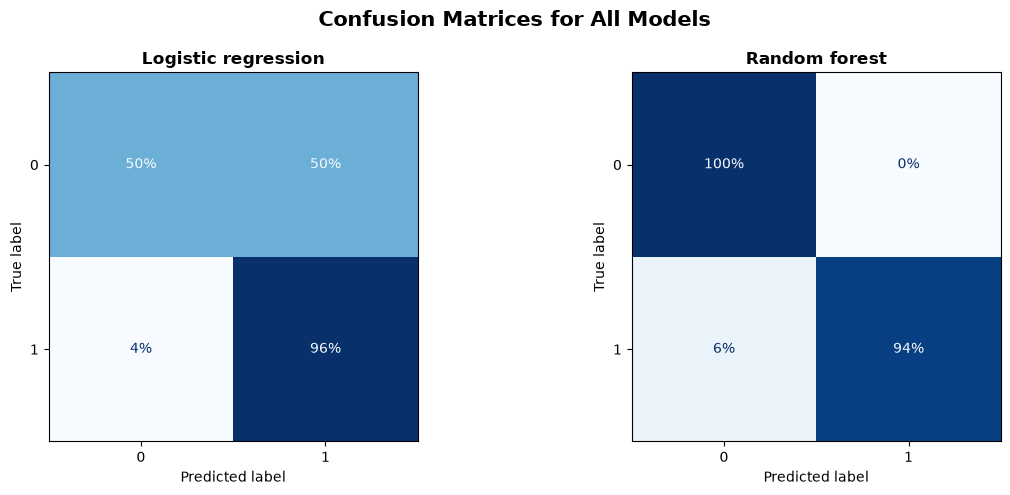

,accuracy,macro precision,macro recall,macro F1,weighted F1,fit time (s)
model,,,,,,
Random forest,0.946,0.864,0.969,0.905,0.950,0.228
Logistic regression,0.893,0.793,0.729,0.755,0.886,0.012


In [76]:
optimised_results = evaluate_models(
    best_models,
    X_train,
    X_test,
    y_train,
    y_test
)
optimised_results

In [ ]:
# Evaluate the best Random Forest model on the test set and print the classification report
y_pred_rf = best_models['Random forest'].predict(X_test)

print(classification_report(
    y_test,
    y_pred_rf,
    zero_division=0
))

              precision    recall  f1-score   support

           0       0.73      1.00      0.84         8
           1       1.00      0.94      0.97        48

    accuracy                           0.95        56
   macro avg       0.86      0.97      0.90        56
weighted avg       0.96      0.95      0.95        56



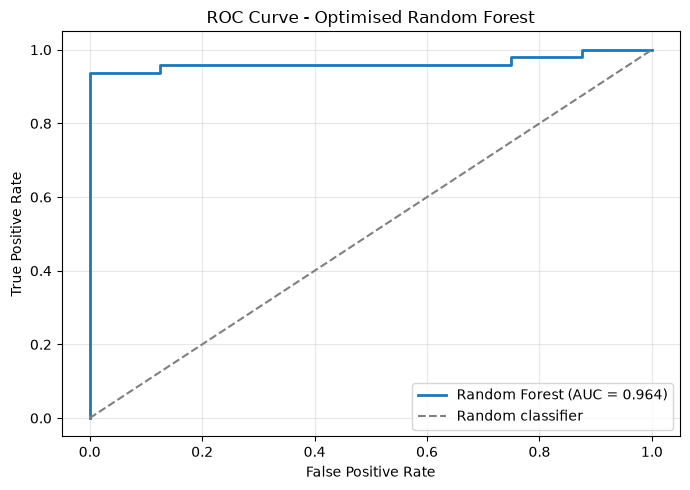

ROC-AUC: 0.964


In [ ]:
# ROC curve visualisation implemented with assistance from ChatGPT.

# Plot ROC curve for the optimised Random Forest model
from sklearn.metrics import (
    roc_curve,
    roc_auc_score,
    RocCurveDisplay
)

# Retrieve optimised Random Forest
rf_model = best_models['Random forest']

# Get probabilities for the positive class (Class 1)
y_prob = rf_model.predict_proba(X_test)[:, 1]

# Calculate ROC values
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

# Calculate AUC
auc_score = roc_auc_score(y_test, y_prob)

# Plot ROC curve
plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f'Random Forest (AUC = {auc_score:.3f})',
    linewidth=2
)

# Random classifier reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    color='grey',
    label='Random classifier'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Optimised Random Forest')

plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"ROC-AUC: {auc_score:.3f}")

In [80]:
# Save the model
import joblib

# Save the optimised Random Forest model
joblib.dump(best_models['Random forest'], 'web_app/lung_cancer_random_forest.pkl')

['web_app/lung_cancer_random_forest.pkl']

In [85]:
# Feature importance implemented with assistance from Claude (Anthropic).

# Permutation importance on the held-out test set for the optimised Random Forest.
# Each feature is shuffled in turn; the drop in macro F1 shows how much the model relies on it.
rf_model = best_models['Random forest']

perm = permutation_importance(
    rf_model,
    X_test,
    y_test,
    scoring='f1_macro',
    n_repeats=30,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    'feature': X_test.columns.str.strip(),
    'permutation mean': perm.importances_mean,
    'permutation std': perm.importances_std,
    'impurity (built-in)': rf_model.feature_importances_
}).sort_values('permutation mean', ascending=False)

importance_df.reset_index(drop=True)

,feature,permutation mean,permutation std,impurity (built-in)
0,ALCOHOL CONSUMING,0.072601,0.034577,0.113415
1,YELLOW_FINGERS,0.068080,0.031877,0.050634
2,COUGHING,0.045876,0.023871,0.049614
3,SWALLOWING DIFFICULTY,0.041194,0.037521,0.079773
4,ALLERGY,0.038584,0.061539,0.128997
5,WHEEZING,0.034006,0.034425,0.057940
6,ANXIETY,0.031316,0.022729,0.047375
7,SHORTNESS OF BREATH,0.021143,0.018489,0.043550
8,CHEST PAIN,0.018298,0.027069,0.048584
9,FATIGUE,0.007877,0.026329,0.076609


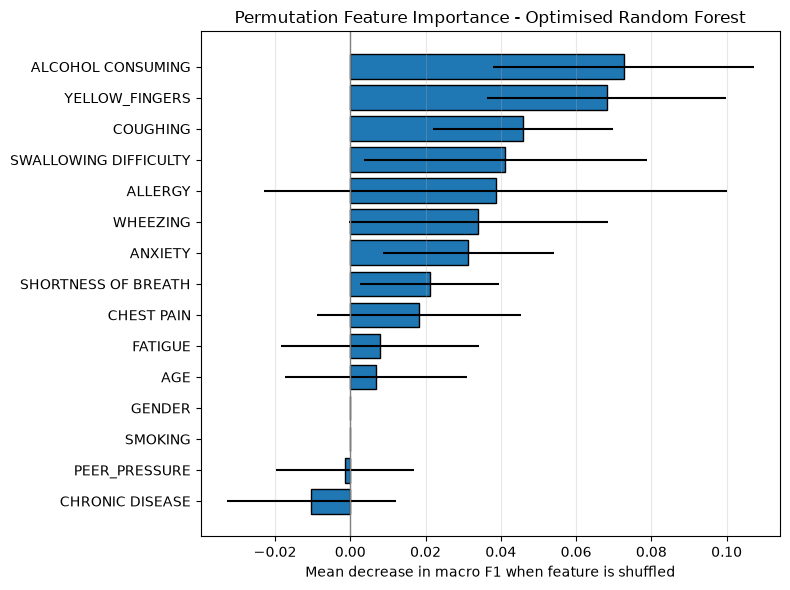

In [86]:
plot_df = importance_df.sort_values('permutation mean', ascending=True)

plt.figure(figsize=(8, 6))
plt.barh(
    plot_df['feature'],
    plot_df['permutation mean'],
    xerr=plot_df['permutation std'],
    edgecolor='black'
)
plt.axvline(0, color='grey', linewidth=1)

plt.xlabel('Mean decrease in macro F1 when feature is shuffled')
plt.title('Permutation Feature Importance - Optimised Random Forest')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()